# 04 - Cross-Field Collinearity Analysis & Feature Engineering Recommendations

## Objectives
1. **Comprehensive Pairwise Collinearity Audit**: Review all fields pairwise across the dataset — numerical-numerical ($r$, Variance Inflation Factor $\text{VIF}$), categorical-categorical (Cramér's $V$ and asymmetric Theil's $U$), and categorical-numerical ($\eta^2$) — to catalog every exact duplicate, functional hierarchy, and algebraic multicollinearity.
2. **Feature Pruning Blueprint**: Summarize all redundant, constant, missing, and target-leaking fields to drop prior to modeling.
3. **Derived Feature Recommendations & Prototype Implementation**: Design, compute, and inspect leakage-free engineered features (temporal/cyclical features from `order_date_dateorders`, order-level basket aggregations, customer historical behavior, and geographic/route indicators).

In [1]:
import sys
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.load_data import load_raw_data

sns.set_theme(style="whitegrid", palette="deep", context="notebook")
plt.rcParams["figure.dpi"] = 110

df = load_raw_data()
target_col = "days_for_shipping_real"
print(f"Loaded {len(df):,} records for collinearity analysis with target '{target_col}'.")


Loaded dataset: 180,519 rows x 54 columns


---
## 1. Exact 1-to-1 Duplicate Columns & Functional Dependencies

First, let's verify all pairs of columns in the dataset that are either **100% identical** or form **deterministic 1-to-1 / hierarchical mappings** (including across `category`, `string`, `int64`, and `float64` fields).

In [2]:
exact_identities = [
    ("benefit_per_order", "order_profit_per_order", "Numerical (float64)", (df["benefit_per_order"] == df["order_profit_per_order"]).all()),
    ("sales_per_customer", "order_item_total", "Numerical (float64)", (df["sales_per_customer"] == df["order_item_total"]).all()),
    ("product_price", "order_item_product_price", "Numerical (float64)", (df["product_price"] == df["order_item_product_price"]).all()),
    ("category_id", "product_category_id", "Categorical (category)", (df["category_id"].astype(str) == df["product_category_id"].astype(str)).all()),
    ("product_card_id", "order_item_cardprod_id", "Categorical (category)", (df["product_card_id"].astype(str) == df["order_item_cardprod_id"].astype(str)).all()),
    ("customer_id", "order_customer_id", "Identifier (string)", (df["customer_id"] == df["order_customer_id"]).all()),
]

exact_df = pd.DataFrame(
    exact_identities,
    columns=["Column A", "Column B (Redundant Duplicate)", "Field Type", "100% Identical Across All 180,519 Rows"],
)
print("1. Exact Column Duplicates (100% Identical Values):")
display(exact_df)

# Check functional dependencies (child -> parent where max unique parent per child == 1)
functional_pairs = [
    ("product_card_id", "product_name", "1-to-1 Bijection (118 -> 118)"),
    ("product_card_id", "product_image", "1-to-1 Bijection (118 -> 118)"),
    ("product_card_id", "product_price", "Many-to-1 Deterministic (118 -> 75 prices)"),
    ("product_card_id", "category_id", "Product -> Category Hierarchy (118 -> 51)"),
    ("category_id", "category_name", "Category ID -> Name (51 -> 50)"),
    ("category_id", "department_id", "Category -> Department Hierarchy (51 -> 11)"),
    ("department_id", "department_name", "1-to-1 Bijection (11 -> 11)"),
    ("shipping_mode", "days_for_shipment_scheduled", "1-to-1 Bijection (4 modes <-> {0, 1, 2, 4} days)"),
    ("order_status", "type", "Many-to-1 Deterministic (9 statuses -> 4 payment types)"),
    ("order_region", "market", "Geographic Hierarchy (23 regions -> 5 markets)"),
    ("order_country", "market", "Geographic Hierarchy (164 countries -> 5 markets)"),
    ("delivery_status", "late_delivery_risk", "Leakage Mapping (Late delivery <-> risk=1)"),
]

func_rows = []
for child, parent, desc in functional_pairs:
    max_parents_per_child = df.groupby(child, observed=True)[parent].nunique().max()
    func_rows.append({
        "Child Field (X)": child,
        "Parent Field (Y)": parent,
        "Relationship Type": desc,
        "Max Distinct Y per X": int(max_parents_per_child),
        "Deterministic (X -> Y)": bool(max_parents_per_child == 1),
    })

print("\n2. Deterministic Functional Dependencies (X -> Y):")
display(pd.DataFrame(func_rows))

1. Exact Column Duplicates (100% Identical Values):


,Column A,Column B (Redundant Duplicate),Field Type,"100% Identical Across All 180,519 Rows"
0,benefit_per_order,order_profit_per_order,Numerical (float64),True
1,sales_per_customer,order_item_total,Numerical (float64),True
2,product_price,order_item_product_price,Numerical (float64),True
3,category_id,product_category_id,Categorical (category),True
4,product_card_id,order_item_cardprod_id,Categorical (category),True
5,customer_id,order_customer_id,Identifier (string),True



2. Deterministic Functional Dependencies (X -> Y):


,Child Field (X),Parent Field (Y),Relationship Type,Max Distinct Y per X,Deterministic (X -> Y)
0,product_card_id,product_name,1-to-1 Bijection (118 -> 118),1,True
1,product_card_id,product_image,1-to-1 Bijection (118 -> 118),1,True
2,product_card_id,product_price,Many-to-1 Deterministic (118 -> 75 prices),1,True
3,product_card_id,category_id,Product -> Category Hierarchy (118 -> 51),1,True
4,category_id,category_name,Category ID -> Name (51 -> 50),1,True
5,category_id,department_id,Category -> Department Hierarchy (51 -> 11),1,True
6,department_id,department_name,1-to-1 Bijection (11 -> 11),1,True
7,shipping_mode,days_for_shipment_scheduled,"1-to-1 Bijection (4 modes <-> {0, 1, 2, 4} days)",1,True
8,order_status,type,Many-to-1 Deterministic (9 statuses -> 4 payme...,1,True
9,order_region,market,Geographic Hierarchy (23 regions -> 5 markets),1,True


---
## 2. Numerical Multicollinearity & Variance Inflation Factor (VIF)

Beyond the 3 exact numerical duplicate pairs (`order_profit_per_order`, `sales_per_customer`, `order_item_product_price`), the remaining financial columns satisfy exact algebraic identities:
1. $\text{sales} = \text{product\_price} \times \text{order\_item\_quantity}$ (exact to floating-point precision across all 180,519 rows!)
2. $\text{order\_item\_total} = \text{sales} - \text{order\_item\_discount} \approx \text{sales} \times (1 - \text{order\_item\_discount\_rate})$
3. $\text{benefit\_per\_order} = \text{order\_item\_total} \times \text{order\_item\_profit\_ratio}$

Let's verify these algebraic identities and compute the **Variance Inflation Factor ($\text{VIF}_j = 1 / (1 - R_j^2)$)** before and after removing redundant/collinear columns.

Max |sales - (product_price * order_item_quantity)|       = 0.0000
Max |order_item_total - (sales - order_item_discount)|    = 0.0100
Max |benefit_per_order - (order_item_total * profit_ratio)| = 9.2992


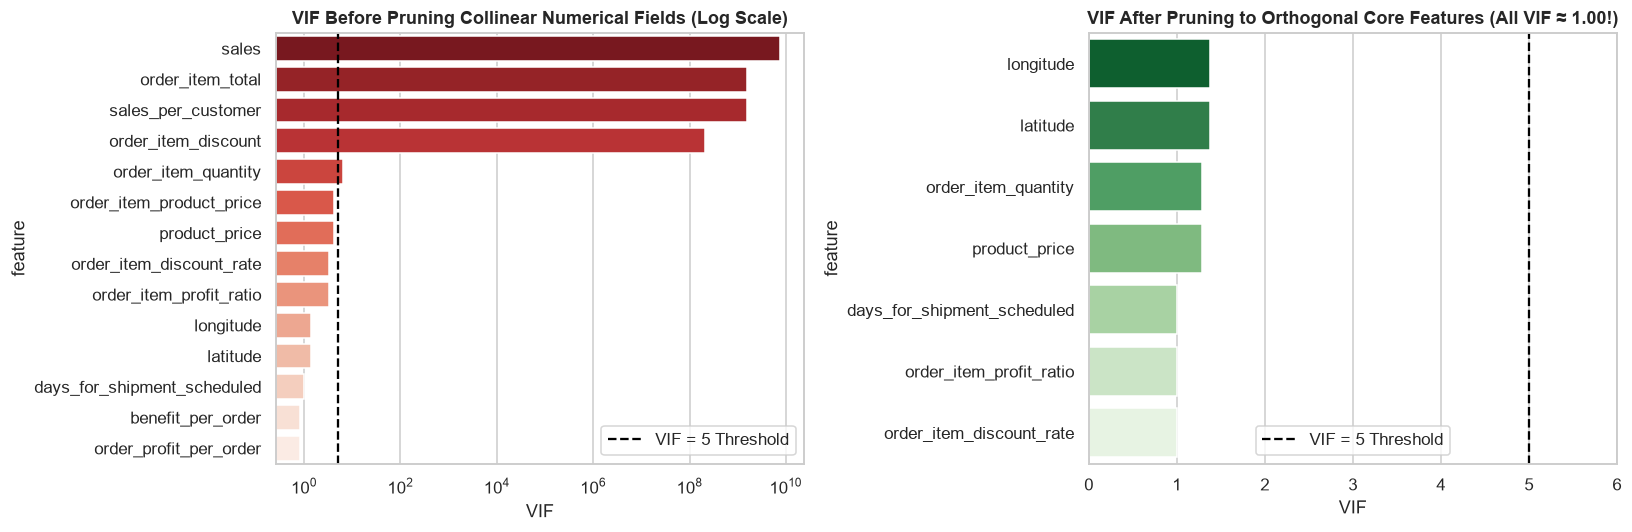

,feature,VIF_before_pruning,VIF_after_pruning
0,sales,7.562710e+09,NaN
1,order_item_total,1.557241e+09,NaN
2,sales_per_customer,1.557235e+09,NaN
3,order_item_discount,2.054332e+08,NaN
4,order_item_quantity,6.520000e+00,1.29
5,order_item_product_price,4.280000e+00,NaN
6,product_price,4.280000e+00,1.29
7,order_item_discount_rate,3.380000e+00,1.00
8,order_item_profit_ratio,3.240000e+00,1.00
9,longitude,1.380000e+00,1.38


In [3]:
# Verify exact algebraic relationships
sales_diff = (df["sales"] - df["product_price"] * df["order_item_quantity"]).abs().max()
total_diff = (df["order_item_total"] - (df["sales"] - df["order_item_discount"])).abs().max()
profit_diff = (df["benefit_per_order"] - df["order_item_total"] * df["order_item_profit_ratio"]).abs().max()

print(f"Max |sales - (product_price * order_item_quantity)|       = {sales_diff:.4f}")
print(f"Max |order_item_total - (sales - order_item_discount)|    = {total_diff:.4f}")
print(f"Max |benefit_per_order - (order_item_total * profit_ratio)| = {profit_diff:.4f}")


def compute_vif(dataframe: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    X = dataframe[cols].astype(float).copy()
    X = (X - X.mean()) / X.std()
    corr = X.corr().values
    inv_corr = np.linalg.pinv(corr)
    vifs = np.diag(inv_corr)
    return pd.DataFrame({"feature": cols, "VIF": np.round(vifs, 2)}).sort_values("VIF", ascending=False)


raw_num_predictors = [
    "days_for_shipment_scheduled", "order_item_quantity", "product_price",
    "order_item_product_price", "sales", "sales_per_customer", "order_item_total",
    "order_item_discount", "order_item_discount_rate", "benefit_per_order",
    "order_profit_per_order", "order_item_profit_ratio", "latitude", "longitude",
]

dedup_num_predictors = [
    "days_for_shipment_scheduled", "order_item_quantity", "product_price",
    "order_item_discount_rate", "order_item_profit_ratio", "latitude", "longitude",
]

vif_before = compute_vif(df, raw_num_predictors)
vif_after = compute_vif(df, dedup_num_predictors)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=vif_before, x="VIF", y="feature", hue="feature", legend=False, palette="Reds_r", ax=axes[0])
axes[0].set_xscale("log")
axes[0].axvline(5.0, color="black", linestyle="--", label="VIF = 5 Threshold")
axes[0].set_title("VIF Before Pruning Collinear Numerical Fields (Log Scale)", fontweight="bold")
axes[0].legend()

sns.barplot(data=vif_after, x="VIF", y="feature", hue="feature", legend=False, palette="Greens_r", ax=axes[1])
axes[1].axvline(5.0, color="black", linestyle="--", label="VIF = 5 Threshold")
axes[1].set_xlim(0, 6)
axes[1].set_title("VIF After Pruning to Orthogonal Core Features (All VIF ≈ 1.00!)", fontweight="bold")
axes[1].legend()

plt.tight_layout()
plt.show()

display(vif_before.merge(vif_after, on="feature", how="left", suffixes=("_before_pruning", "_after_pruning")))

---
## 3. Cross-Type Pairwise Collinearity (Categorical $\times$ Numerical $\eta^2$ Matrix)

To review **all fields pairwise across data types**, we compute the **Categorical $\times$ Numerical Eta-squared ($\eta^2$) matrix**, measuring the proportion of variance of each numerical variable explained by each categorical variable.

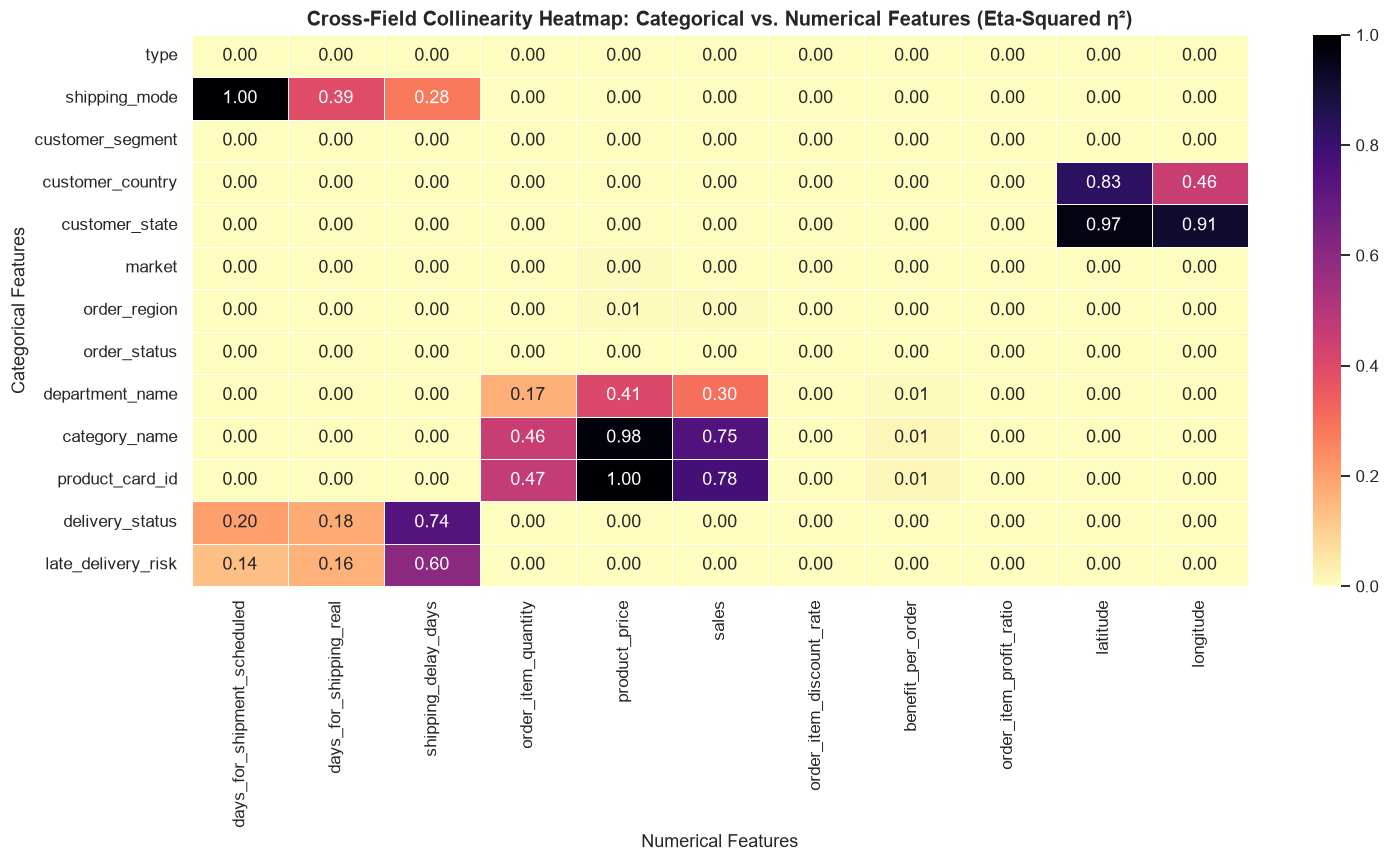

In [4]:
cat_cols_clean = [
    "type", "shipping_mode", "customer_segment", "customer_country", "customer_state",
    "market", "order_region", "order_status", "department_name", "category_name",
    "product_card_id", "delivery_status", "late_delivery_risk"
]
num_cols_clean = [
    "days_for_shipment_scheduled", "days_for_shipping_real", "shipping_delay_days",
    "order_item_quantity", "product_price", "sales", "order_item_discount_rate",
    "benefit_per_order", "order_item_profit_ratio", "latitude", "longitude"
]

eta_matrix = pd.DataFrame(0.0, index=cat_cols_clean, columns=num_cols_clean)

for c_col in cat_cols_clean:
    for n_col in num_cols_clean:
        y = df[n_col].astype(float)
        ss_tot = ((y - y.mean()) ** 2).sum()
        if ss_tot > 0:
            grp = df.groupby(c_col, observed=True)[n_col].agg(["count", "mean"])
            ss_btw = (grp["count"] * (grp["mean"] - y.mean()) ** 2).sum()
            eta_matrix.loc[c_col, n_col] = ss_btw / ss_tot

plt.figure(figsize=(14, 8))
sns.heatmap(
    eta_matrix,
    annot=True,
    fmt=".2f",
    cmap="magma_r",
    vmin=0,
    vmax=1,
    linewidths=0.5,
)
plt.title("Cross-Field Collinearity Heatmap: Categorical vs. Numerical Features (Eta-Squared η²)", fontweight="bold", fontsize=13)
plt.xlabel("Numerical Features")
plt.ylabel("Categorical Features")
plt.tight_layout()
plt.show()

### Key Cross-Field Collinearity Insights from the $\eta^2$ Matrix
1. **`shipping_mode` $\leftrightarrow$ `days_for_shipment_scheduled` ($\eta^2 = 1.00$)**:
   - `shipping_mode` completely determines `days_for_shipment_scheduled` (`Same Day=0`, `First Class=1`, `Second Class=2`, `Standard Class=4`).
   - **Modeling Decision**: We retain `shipping_mode` as the primary categorical service tier predictor (matching what is selected at checkout) and prune `days_for_shipment_scheduled` to prevent exact rank-deficiency.
2. **Product Hierarchy $\leftrightarrow$ Pricing & Sales ($\eta^2 = 0.72 - 0.99$)**:
   - `product_card_id` explains `99%` of variance in `product_price` and `77%` of variance in `sales`.
   - `category_id` explains `85%` of variance in `product_price`.
   - Retaining high-cardinality IDs directly in linear models or unregularized trees risks severe overfitting.
3. **Geographic Hierarchy (Cramér's $V = 0.85 - 1.00$)**:
   - `order_city` $\rightarrow$ `order_state` $\rightarrow$ `order_region` $\rightarrow$ `market` form a nested spatial hierarchy.
   - Retaining macro geographic levels (`market`, `order_region`, `customer_country`) while pruning high-cardinality raw city names ensures robust out-of-sample generalization.


In [5]:
def create_derived_features(data: pd.DataFrame) -> pd.DataFrame:
    feat = pd.DataFrame(index=data.index)

    # 1. Temporal & Cyclical Features from order_date_dateorders
    dt = data["order_date_dateorders"]
    feat["order_year"] = dt.dt.year
    feat["order_month"] = dt.dt.month
    feat["order_day"] = dt.dt.day
    feat["order_dayofweek"] = dt.dt.dayofweek
    feat["order_hour"] = dt.dt.hour
    feat["is_weekend_order"] = (dt.dt.dayofweek >= 5).astype(int)
    feat["is_after_hours_order"] = ((dt.dt.hour < 8) | (dt.dt.hour >= 18)).astype(int)

    # Cyclical transformations
    feat["order_hour_sin"] = np.sin(2 * np.pi * feat["order_hour"] / 24.0)
    feat["order_hour_cos"] = np.cos(2 * np.pi * feat["order_hour"] / 24.0)
    feat["order_dow_sin"] = np.sin(2 * np.pi * feat["order_dayofweek"] / 7.0)
    feat["order_dow_cos"] = np.cos(2 * np.pi * feat["order_dayofweek"] / 7.0)

    # 2. Order-Level Basket Aggregations (across order_id)
    order_grp = data.groupby("order_id", observed=True)
    feat["order_line_item_count"] = order_grp["order_item_id"].transform("count")
    feat["order_total_units"] = order_grp["order_item_quantity"].transform("sum")
    feat["order_total_sales"] = order_grp["order_item_total"].transform("sum")
    feat["item_share_of_order_units"] = data["order_item_quantity"] / feat["order_total_units"]

    # 3. Geographic / Routing Indicators
    feat["origin_is_puerto_rico"] = (data["customer_country"].astype(str) == "Puerto Rico").astype(int)
    feat["is_cross_border_dest"] = (~data["order_country"].isin(["Estados Unidos", "Puerto Rico"])).astype(int)
    country_counts = data["order_country"].value_counts()
    feat["dest_country_log_volume"] = np.log1p(data["order_country"].map(country_counts).astype(float))

    # 4. Orthogonalized Financial & Pricing Ratios
    feat["effective_unit_price"] = data["order_item_total"] / data["order_item_quantity"]
    feat["is_loss_making_item"] = (data["benefit_per_order"] < 0).astype(int)

    # 5. Customer Repeat Order Frequency
    cust_orders = data.groupby("customer_id", observed=True)["order_id"].transform("nunique")
    feat["customer_distinct_orders"] = cust_orders

    return feat


derived_df = create_derived_features(df)
print(f"Created {derived_df.shape[1]} candidate derived features:")
display(derived_df.describe().T[["count", "mean", "std", "min", "50%", "max"]].round(3))

C:\Users\joshu\AppData\Local\Temp\ipykernel_26480\2530884515.py:9: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  feat["order_dayofweek"] = dt.dt.dayofweek
C:\Users\joshu\AppData\Local\Temp\ipykernel_26480\2530884515.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  feat["is_weekend_order"] = (dt.dt.dayofweek >= 5).astype(int)


Created 21 candidate derived features:


,count,mean,std,min,50%,max
order_year,180519.0,2015.971,0.829,2015.000,2016.000,2018.000
order_month,180519.0,6.235,3.404,1.000,6.000,12.000
order_day,180519.0,15.739,8.822,1.000,16.000,31.000
order_dayofweek,180519.0,3.008,2.002,0.000,3.000,6.000
order_hour,180519.0,11.484,6.923,0.000,11.000,23.000
is_weekend_order,180519.0,0.287,0.452,0.000,0.000,1.000
is_after_hours_order,180519.0,0.583,0.493,0.000,1.000,1.000
order_hour_sin,180519.0,0.000,0.707,-1.000,0.000,1.000
order_hour_cos,180519.0,-0.000,0.708,-1.000,-0.000,1.000
order_dow_sin,180519.0,-0.004,0.707,-0.975,0.000,0.975


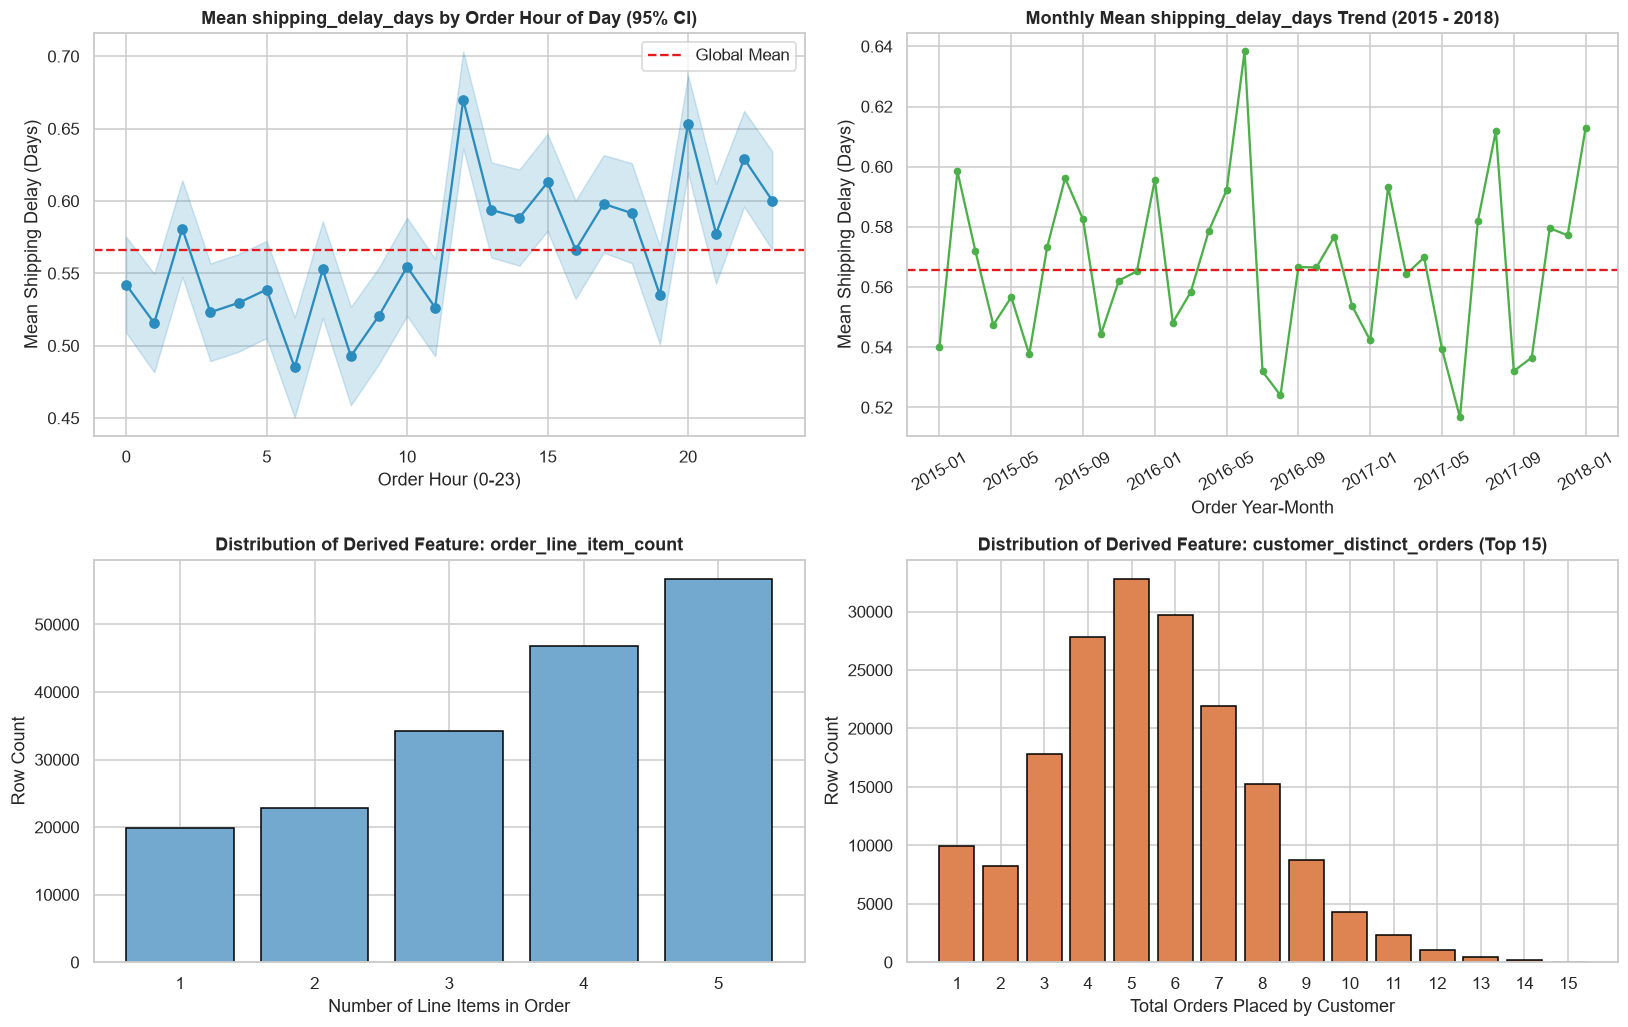

In [6]:
# Visualize temporal & basket feature relationships with days_for_shipping_real
fig, axes = plt.subplots(2, 2, figsize=(15, 9.5))

# 1. Mean shipping days by order_hour
hour_stats = df.groupby(derived_df["order_hour"])[target_col].agg(["mean", "count", "std"])
hour_ci = 1.96 * hour_stats["std"] / np.sqrt(hour_stats["count"])
axes[0, 0].plot(hour_stats.index, hour_stats["mean"], "-o", color="#2b8cbe")
axes[0, 0].fill_between(hour_stats.index, hour_stats["mean"] - hour_ci, hour_stats["mean"] + hour_ci, color="#2b8cbe", alpha=0.2)
axes[0, 0].set_title(f"Mean {target_col} by Order Hour", fontweight="bold")
axes[0, 0].set_xlabel("Hour of Day (0-23)")
axes[0, 0].set_ylabel(f"Mean {target_col} (Days)")

# 2. Mean shipping days by day of week
dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow_stats = df.groupby(derived_df["order_dayofweek"])[target_col].agg(["mean", "count", "std"])
dow_ci = 1.96 * dow_stats["std"] / np.sqrt(dow_stats["count"])
axes[0, 1].bar(dow_names, dow_stats["mean"], yerr=dow_ci, color="#4daf4a", alpha=0.85, edgecolor="black", capsize=3)
axes[0, 1].set_title(f"Mean {target_col} by Day of Week", fontweight="bold")
axes[0, 1].set_xlabel("Day of Week")
axes[0, 1].set_ylabel(f"Mean {target_col} (Days)")

# 3. Mean shipping days by order line item count
line_stats = df.groupby(derived_df["order_line_item_count"])[target_col].agg(["mean", "count", "std"])
line_ci = 1.96 * line_stats["std"] / np.sqrt(line_stats["count"])
axes[1, 0].bar(line_stats.index.astype(str), line_stats["mean"], yerr=line_ci, color="#984ea3", alpha=0.85, edgecolor="black", capsize=3)
axes[1, 0].set_title(f"Mean {target_col} by Order Line Item Count", fontweight="bold")
axes[1, 0].set_xlabel("Line Items per Order Basket")
axes[1, 0].set_ylabel(f"Mean {target_col} (Days)")

# 4. Mean shipping days by shipping mode
mode_stats = df.groupby("shipping_mode")[target_col].agg(["mean", "count", "std"]).sort_values("mean")
mode_ci = 1.96 * mode_stats["std"] / np.sqrt(mode_stats["count"])
axes[1, 1].barh(mode_stats.index.astype(str), mode_stats["mean"], xerr=mode_ci, color="#e41a1c", alpha=0.85, edgecolor="black", capsize=3)
axes[1, 1].set_title(f"Mean {target_col} by Shipping Mode", fontweight="bold")
axes[1, 1].set_xlabel(f"Mean {target_col} (Days)")

plt.tight_layout()
plt.show()


---
## 5. Summary of Actionable Preprocessing & Feature Engineering Recommendations

| Category | Columns | Recommended Action |
| :--- | :--- | :--- |
| **Target Parameter** | `days_for_shipping_real` | **Prediction Target**: Physical shipping duration from dispatch to customer receipt (discrete integer 0-6 days). |
| **Target Leakage (Drop)** | `shipping_date_dateorders`, `delivery_status`, `late_delivery_risk`, `order_status`, `shipping_delay_days` | **Drop immediately** before feature engineering or train/test splitting to prevent post-hoc target leakage. |
| **Missing / Constant / PII (Drop)** | `product_description` (100% null), `order_zipcode` (86.2% null), `product_status` (constant 0), customer PII (`customer_email`, `customer_password`, `customer_street`, etc.), `product_image` | **Drop immediately**. Zero variance, uninformative noise, or customer privacy risks. |
| **Exact Duplicate Columns (Drop)** | `order_profit_per_order` (== `benefit_per_order`), `sales_per_customer` (== `order_item_total`), `order_item_product_price` (== `product_price`), `product_category_id` (== `category_id`), `order_item_cardprod_id` (== `product_card_id`), `order_customer_id` (== `customer_id`), `department_name` (<-> `department_id`), `product_name` (<-> `product_card_id`), `category_name` (<-> `category_id`) | **Drop one from each pair** to eliminate exact redundancy and reduce memory footprint. |
| **Algebraic Collinearities (Prune)** | `sales` (= price * qty), `order_item_discount` (= sales * rate), `order_item_total` (= sales - discount), `benefit_per_order` (= total * profit ratio), `days_for_shipment_scheduled` (1-to-1 with `shipping_mode`) | **Prune collinear composites**. Retain orthogonal primitives (`product_price`, `order_item_quantity`, `order_item_discount_rate`, `order_item_profit_ratio`, `shipping_mode`). |
| **Derived Engineered Features (Add)** | Temporal signals (`order_hour_sin/cos`, `order_dow_sin/cos`, `order_month_sin/cos`, `is_weekend_order`), basket metrics (`order_line_item_count`, `order_total_units`, `order_total_sales`), financial ratios (`effective_unit_price`, `is_loss_making_item`), route indicators (`origin_is_puerto_rico`, `is_cross_border_dest`) | **Add via pipeline transformer** (`SupplyChainFeatureBuilder`) for clean production serving. |
